# Data Preparation for Machine Learning

This notebook provides a step-by-step guide to cleaning tree data from Grenoble in order to predict the planting year.

## Objective
Prepare the data to train a Machine Learning model that can predict missing tree planting years.

## Notebook Outline
1. Import libraries and load data  
2. Initial data exploration  
3. Data cleaning  
4. Save the data as a pickle file

## 1. Importing Libraries and Loading Data

We use several essential Python libraries for data analysis:
- pandas: for data manipulation  
- numpy: for numerical computations  
- matplotlib and seaborn: for visualization  
- sklearn: for preparing data for Machine Learning

In [1]:
#%pip install -r '../requirements.txt'

# Libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Loading the Data
df = pd.read_csv('../arbres_grenoble_epsg4326.csv', sep=',', encoding='utf-8')

# Display the first few rows
print('Data preview:')
display(df.head())

# Dataset information
print('\nDataset information:')
display(df.info())

Data preview:


,elem_point_id,code,nom,genre,genre_desc,categorie,categorie_desc,sous_categorie,sous_categorie_desc,code_parent,...,diametrearbre,causeabattage,collectivite,stationmetro,hauteurarbre,portarbre,structure,forme,typenature,geo_point_2d
0,34835,ESP36318,AR36318,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP237,...,NaN,NaN,Grenoble Alpes Métropole,NaN,NaN,NaN,Métropole de Grenoble,NaN,NaN,"45.167098421885385,5.740131798404362"
1,34836,ESP36319,AR36319,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP237,...,NaN,NaN,Grenoble Alpes Métropole,NaN,NaN,NaN,Métropole de Grenoble,NaN,NaN,"45.16710682038838,5.740199792549315"
2,34837,ESP36320,AR36320,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP237,...,NaN,NaN,Grenoble Alpes Métropole,NaN,NaN,NaN,Métropole de Grenoble,NaN,NaN,"45.167115270975415,5.740265608803635"
3,34838,ESP36321,AR36321,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP237,...,NaN,NaN,Grenoble Alpes Métropole,NaN,NaN,NaN,Métropole de Grenoble,NaN,NaN,"45.16712715617142,5.740349032579623"
4,34839,ESP36322,AR36322,VEG,VEGETATION,ESP01,Arbre,ESP151,Arbre de voirie,ESP237,...,NaN,NaN,Grenoble Alpes Métropole,NaN,NaN,NaN,Métropole de Grenoble,NaN,NaN,"45.167144245872265,5.740471081600832"



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 31670 entries, 0 to 31669
Data columns (total 38 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   elem_point_id          31670 non-null  int64  
 1   code                   31670 non-null  str    
 2   nom                    31670 non-null  str    
 3   genre                  31670 non-null  str    
 4   genre_desc             31670 non-null  str    
 5   categorie              31670 non-null  str    
 6   categorie_desc         31670 non-null  str    
 7   sous_categorie         31670 non-null  str    
 8   sous_categorie_desc    31670 non-null  str    
 9   code_parent            31670 non-null  str    
 10  code_parent_desc       31670 non-null  str    
 11  adr_secteur            31670 non-null  int64  
 12  bien_reference         31670 non-null  str    
 13  genre_bota             30859 non-null  str    
 14  espece                 29370 non-null  str 

None

In [3]:
df_traitch = df['traitementchenilles'].dropna()
df_traitch.value_counts()

traitementchenilles
Haute      1086
Moyenne     853
Basse       127
Name: count, dtype: int64

In [4]:
df['raisondeplantation'].value_counts()

raisondeplantation
Nouveau         2896
Remplacement     388
Existant           3
Name: count, dtype: int64

In [5]:
for i in df.columns:
    print(df[i].value_counts())

elem_point_id
34835    1
34836    1
34837    1
34838    1
34839    1
        ..
44741    1
44742    1
44841    1
44842    1
44982    1
Name: count, Length: 31670, dtype: int64
code
ESP36318    1
ESP36319    1
ESP36320    1
ESP36321    1
ESP36322    1
           ..
ESP40744    1
ESP40745    1
ESP40796    1
ESP40797    1
ESP40913    1
Name: count, Length: 31670, dtype: int64
nom
AR36318    1
AR36319    1
AR36320    1
AR36321    1
AR36322    1
          ..
AR40744    1
AR40745    1
AR40796    1
AR40797    1
AR40913    1
Name: count, Length: 31670, dtype: int64
genre
VEG    31670
Name: count, dtype: int64
genre_desc
VEGETATION    31670
Name: count, dtype: int64
categorie
ESP01    31670
Name: count, dtype: int64
categorie_desc
Arbre    31670
Name: count, dtype: int64
sous_categorie
ESP174    15222
ESP151    12473
ESP065     2475
ESP187     1500
Name: count, dtype: int64
sous_categorie_desc
Arbre d'espaces ouverts      15222
Arbre de voirie              12473
Arbre d'enceintes fermées     24

## 2. Initial Data Exploration

Before starting the cleaning process, it's crucial to understand our data:
- What columns are available?  
- What types of data do we have?  
- Are there any missing values?

In [6]:
# Descriptive Statistics
df.dtypes
# Analysis of Missing Values
x=df.isna().sum()/len(df)*100
print(x)

elem_point_id              0.000000
code                       0.000000
nom                        0.000000
genre                      0.000000
genre_desc                 0.000000
categorie                  0.000000
categorie_desc             0.000000
sous_categorie             0.000000
sous_categorie_desc        0.000000
code_parent                0.000000
code_parent_desc           0.000000
adr_secteur                0.000000
bien_reference             0.000000
genre_bota                 2.560783
espece                     7.262393
variete                   85.478371
stadededeveloppement      13.179665
equipe                   100.000000
remarques                 83.227029
anneedeplantation          6.769814
raisondeplantation        89.621093
traitementchenilles       93.476476
courrier                 100.000000
identifiantplu            98.146511
typeimplantationplu       84.313230
intituleprotectionplu     98.146511
anneeabattage            100.000000
essouchement             100

### Visualisation of missing values

<Axes: >

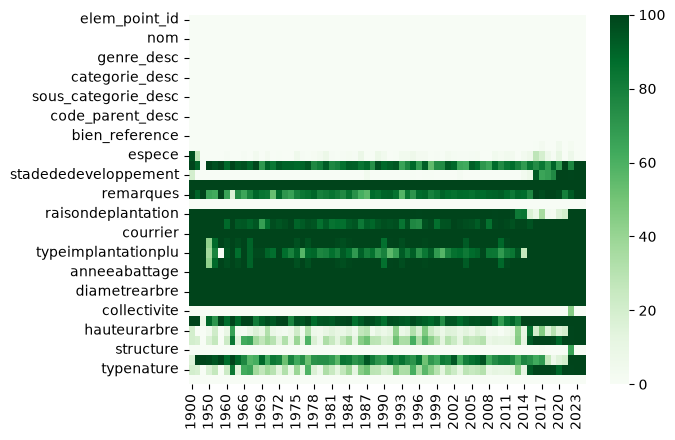

In [7]:
# Creation of a heatmap to visualize missing values
#
percent_missing=pd.DataFrame()
for i in df['anneedeplantation'].value_counts().index.sort_values():
    percent_missing[i]=df[df['anneedeplantation']==int(i)].isna().sum()/len(df[df['anneedeplantation']==int(i)])*100

percent_missing

sns.heatmap(percent_missing, cmap='Greens')

<Axes: >

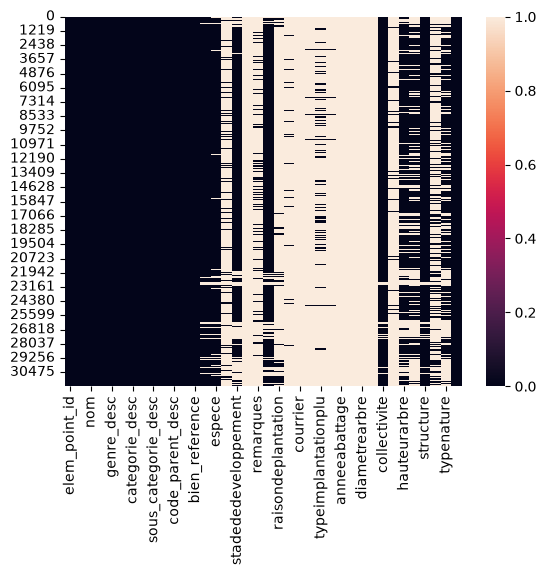

In [8]:
sns.heatmap(df.isna())

## 3. Data Cleaning

### 3.1 After the initial analysis, we will:
1. Remove rows without a planting year **'annedeplantation'**
2. Drop columns that are irrelevant for prediction  
3. Extract geographic coordinates

In [9]:
# 1. Remove rows without a planting year **'annedeplantation'**
df = df[df['anneedeplantation'].notna()]

### 🔍 3.2 Cleaning Unnecessary Columns

We will:

- Remove columns with more than **40% missing values**  
- Remove columns that are **too specific** (e.g., unique identifiers), which don't provide useful information for machine learning  
- Remove columns that contain redundant or unhelpful information

In [10]:
# 2 Remove overly specific columns, such as the 'elem_point_id' column

df = df.drop(columns = ['elem_point_id', 'code', 'nom', 'categorie', 'categorie_desc', 'bien_reference', 'collectivite', 'typenature', 'genre', 'genre_desc'])

In [11]:
missing_percentage = df.isnull().mean() * 100
columns_to_drop = missing_percentage[missing_percentage > 40].index
df = df.drop(columns=columns_to_drop)

In [12]:
# 3. Extract geographic coordinates
df[['latitude', 'longitude']] = df['geo_point_2d'].str.split(',', expand=True)
df = df.drop(columns = ['geo_point_2d'])

In [13]:
df.describe(include='all')

,sous_categorie,sous_categorie_desc,code_parent,code_parent_desc,adr_secteur,genre_bota,espece,stadededeveloppement,anneedeplantation,hauteurarbre,portarbre,structure,latitude,longitude
count,29526,29526,29526,29526,29526.000000,29486,28313,27018,29526.000000,23738,18336,29376,29526,29526
unique,4,4,1462,1462,NaN,118,282,3,NaN,3,6,4,29526,29526
top,ESP174,Arbre d'espaces ouverts,ESP995,Prc Echangeurs Bastion St Roch,NaN,Acer,acerifolia,Arbre adulte,NaN,de 10 m à 20 m,Libre,Métropole de Grenoble,45.167098421885385,5.740131798404362
freq,14345,14345,369,369,NaN,4862,3797,19776,NaN,11418,9132,14352,1,1
mean,NaN,NaN,NaN,NaN,248.442085,NaN,NaN,NaN,1990.445099,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,3047.759858,NaN,NaN,NaN,18.174352,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,1900.000000,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,2.000000,NaN,NaN,NaN,1975.000000,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,4.000000,NaN,NaN,NaN,1987.000000,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,5.000000,NaN,NaN,NaN,2006.000000,NaN,NaN,NaN,NaN,NaN


## 4. Save to data to a pickle file

In [14]:
# Save to data to a pickle file
df.to_pickle('arbres_clean_Laura.pkl')

## Conclusion

We have completed several important cleaning steps:
1. Removed irrelevant columns or those with too many missing values  
2. Extracted geographic coordinates  

The data is now ready for the next steps of the project.